Original Dataset:
    Annual Income  Spending Score
0              15              20
1              16              22
2              17              18
3              18              25
4              19              23
5              20              21
6              60              60
7              62              65
8              63              62
9              65              68
10             67              64
11             68              61
12            100              20
13            102              25
14            105              22
15            107              18
16            108              24
17            110              21

Clustering Results:
    Annual Income  Spending Score  KMeans Cluster  Hierarchical Cluster
0              15              20               2                     1
1              16              22               2                     1
2              17              18               2                     1
3              18          

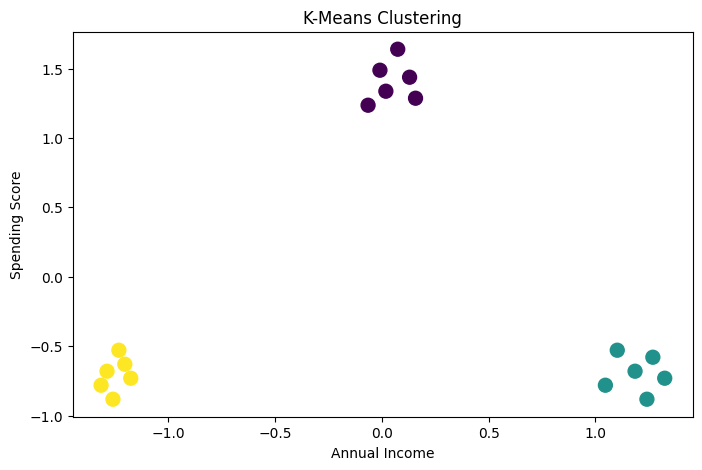

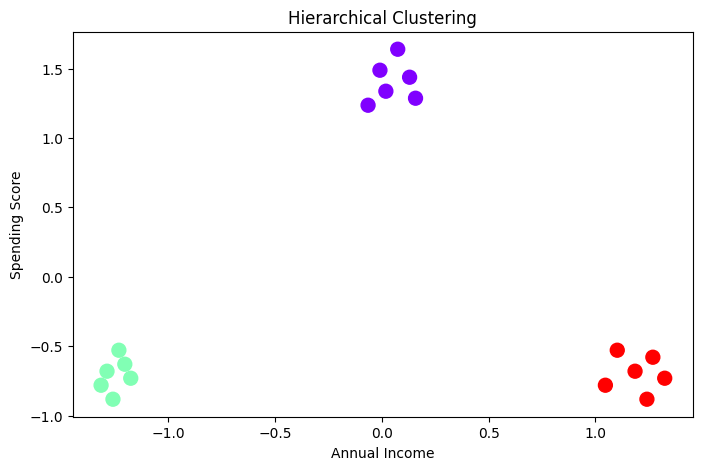

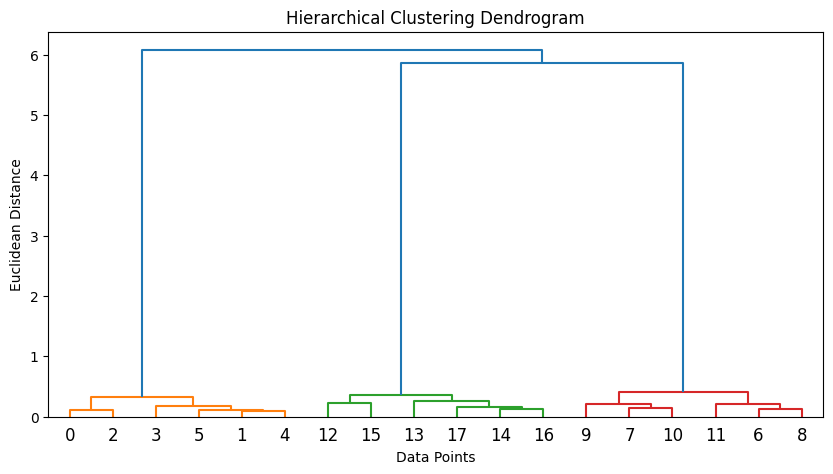


Clustering Comparison:
      Algorithm  Silhouette Score
0       K-Means          0.912587
1  Hierarchical          0.912587


In [1]:
#import
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

# Create Dataset
data = {
    'Annual Income': [15, 16, 17, 18, 19, 20,
                      60, 62, 63, 65, 67, 68,
                      100, 102, 105, 107, 108, 110],
    'Spending Score': [20, 22, 18, 25, 23, 21,
                       60, 65, 62, 68, 64, 61,
                       20, 25, 22, 18, 24, 21]
}

df = pd.DataFrame(data)
print("Original Dataset:")
print(df)

# Data Preprocessing
scaler = StandardScaler()
X = scaler.fit_transform(df)

# K-Means Clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X)
df['KMeans Cluster'] = kmeans_labels

# Hierarchical Clustering
hierarchical = AgglomerativeClustering(
    n_clusters=3, linkage='ward'
)
hierarchical_labels = hierarchical.fit_predict(X)
df['Hierarchical Cluster'] = hierarchical_labels

print("\nClustering Results:")
print(df)

# K-Means Visualization
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=kmeans_labels,
            cmap='viridis', s=100)
plt.title("K-Means Clustering")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.show()

# Hierarchical Visualization
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=hierarchical_labels,
            cmap='rainbow', s=100)
plt.title("Hierarchical Clustering")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.show()

# Dendrogram
Z = linkage(X, method='ward')
plt.figure(figsize=(10, 5))
dendrogram(Z)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")
plt.show()

# Compare Silhouette Scores
kmeans_score = silhouette_score(X, kmeans_labels)
hierarchical_score = silhouette_score(X, hierarchical_labels)

comparison = pd.DataFrame({
    'Algorithm': ['K-Means', 'Hierarchical'],
    'Silhouette Score': [kmeans_score, hierarchical_score]
})

print("\nClustering Comparison:")
print(comparison)
